# Tree genomes: random trees, mutation, crossover

A tree genome describes a robot body as a tree of modules: a core at the root, with bricks and hinges attached to its faces. This is the genotype that genetic-programming operators work on. In this notebook you draw random trees, save and load one, apply each of the four mutation operators, and cross two parents over. Every result is checked with `validate_genome_dict`, so a broken operator fails the notebook. No graphics backend is needed.

In [1]:
# Standard library
import copy
import random
from pathlib import Path

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
import networkx as nx

In [3]:
# Local libraries
from ariel import console
from ariel.ec.genotypes.tree import (
    TreeGenome,
    crossover_subtree,
    get_tree_depth,
    load_genome,
    mutate_hoist,
    mutate_replace_node,
    mutate_shrink,
    mutate_subtree_replacement,
    random_tree,
    save_genome,
)
from ariel.ec.genotypes.tree.validation import validate_genome_dict

In [4]:
# Seed and the output folder
SEED = 42
random.seed(SEED)
MODULES = 8
PAIRS = 100
DATA = Path.cwd() / "__data__" / "tree_genome"
DATA.mkdir(parents=True, exist_ok=True)

## Drawing a genome

One small helper draws a tree with the core on the left, one column per depth, and a colour per module type. The other sections reuse it.

In [5]:
COLOURS = {"CORE": "tab:red", "BRICK": "tab:blue", "HINGE": "tab:green"}


def draw(genome: TreeGenome, axis: plt.Axes, title: str) -> None:
    graph = genome.to_networkx()
    depths = nx.shortest_path_length(graph, source=0)
    for node, depth in depths.items():
        graph.nodes[node]["depth"] = depth
    positions = nx.multipartite_layout(graph, subset_key="depth")
    colours = [COLOURS[genome.nodes[n].type] for n in graph.nodes]
    nx.draw(
        graph,
        positions,
        ax=axis,
        node_color=colours,
        with_labels=True,
        font_color="white",
    )
    axis.set_title(f"{title} ({len(genome.nodes)} modules)")

In [6]:
# Checks: the helper draws one dot per module, coloured by its type,
# and counts them in the title; the random state is put back, so the
# trees below stay the same
state = random.getstate()
sample = random_tree(MODULES)
random.setstate(state)
fig, axis = plt.subplots()
draw(sample, axis, "t")
plt.close(fig)
assert axis.get_title() == f"t ({len(sample.nodes)} modules)"
assert len(axis.collections[0].get_offsets()) == len(sample.nodes)

## A random tree

`random_tree(n)` grows a valid tree of up to `n` modules from the core.

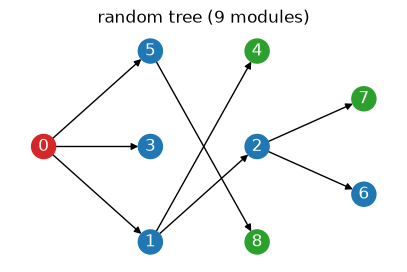

depth 3, modules 9

In [7]:
tree = random_tree(MODULES)
fig, axis = plt.subplots(figsize=(5, 3))
draw(tree, axis, "random tree")
plt.show()
console.print(f"depth {get_tree_depth(tree)}, modules {len(tree.nodes)}")
validate_genome_dict(tree.to_dict())
assert len(tree.nodes) == MODULES + 1  # the core plus MODULES modules

## Save and load

`save_genome` writes the genome as JSON and `load_genome` reads it back equal.

In [8]:
path = DATA / "tree.json"
save_genome(tree, str(path))
loaded = load_genome(str(path))
assert path.is_file()
assert loaded == tree

## Four mutations

Each operator changes a copy of the tree in place: replace one module, replace a whole subtree with a new random one, shrink a branch, or hoist a subtree up to its grandparent. The first panel is the original.

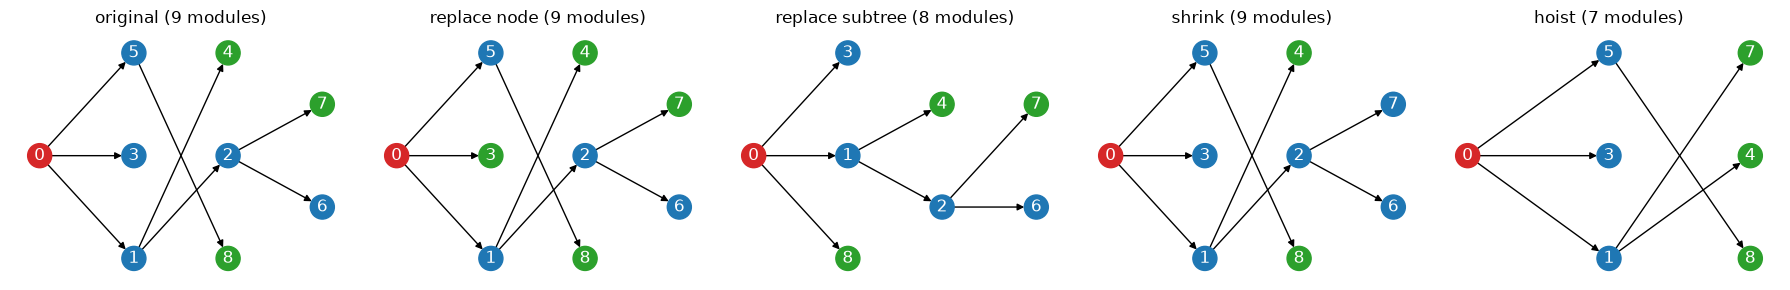

In [9]:
mutations = {
    "replace node": mutate_replace_node,
    "replace subtree": mutate_subtree_replacement,
    "shrink": mutate_shrink,
    "hoist": mutate_hoist,
}
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
draw(tree, axes[0], "original")
mutants = {}
for axis, (name, mutate) in zip(axes[1:], mutations.items(), strict=True):
    mutant = copy.deepcopy(tree)
    mutate(mutant)
    mutants[name] = mutant
    draw(mutant, axis, name)
plt.tight_layout()
plt.show()

In [10]:
for mutant in mutants.values():
    validate_genome_dict(mutant.to_dict())
assert tree == load_genome(str(path))  # the original was not touched
assert len(mutants) == len(mutations)
assert any(mutant != tree for mutant in mutants.values())  # something changed

## Subtree crossover

`crossover_subtree` swaps a random subtree of one parent with a random subtree of the other and returns two children; the parents stay as they were. The pictures show two parents and their children.

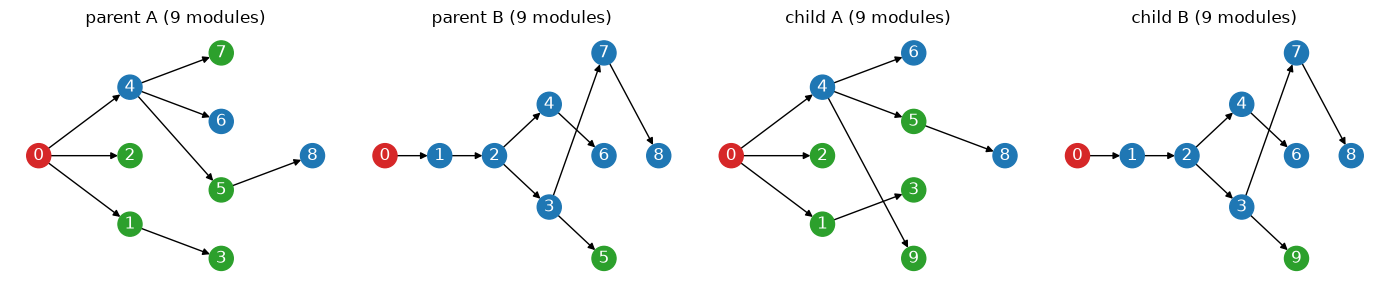

In [11]:
parent_a = random_tree(MODULES)
parent_b = random_tree(MODULES)
child_a, child_b = crossover_subtree(parent_a, parent_b)
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for axis, (title, genome) in zip(
    axes,
    [
        ("parent A", parent_a),
        ("parent B", parent_b),
        ("child A", child_a),
        ("child B", child_b),
    ],
    strict=True,
):
    draw(genome, axis, title)
plt.tight_layout()
plt.show()
validate_genome_dict(child_a.to_dict())
validate_genome_dict(child_b.to_dict())

Over many random pairs the children are valid, and most differ from their parents (the swap really happens).

In [12]:
changed = 0
for _ in range(PAIRS):
    a, b = random_tree(MODULES), random_tree(MODULES)
    first, second = crossover_subtree(a, b)
    validate_genome_dict(first.to_dict())
    validate_genome_dict(second.to_dict())
    changed += first != a or second != b
console.print(
    f"{changed} of {PAIRS} pairs gave a child that differs from its parents"
)
assert changed > PAIRS // 2

98 of 100 pairs gave a child that differs from its parents